

### Describtion of the problem:
#### Look at the images and consider how to distinguish between fat and meat.
In colour - meet is red, fat is white.
#### Which visual changes are apparant in the salami over the 28 days?
It gets darker around the edges and the white stripe around the corner shows up. Also, it seems that fat is more apparent, the "bulbs" are also larger (they appear in larger chunks). The surface seems more smooth. The edge is less circullar. I also think it could have gotten smaller? 
#### How can these changes be measured from the images?
* We could look into color distributions, color ratios. of red to white
* look for single big white chunks by applying circular filters?
* the same for black around the edges
* Apply some filters to find these non-smooth areas (very apparent in the beggining).  
* measure the area and ovalness of the salami
#### Load a multi spectral image in MATLAB or PYTHON and investigate the data.
BELOW

In [37]:
import helper_functions.helpFunctions as hf

dirIn = "./data/"

multiIm, annotationIm = hf.loadMulti(
    "multispectral_day20.mat", "annotation_day20.png", dirIn
)

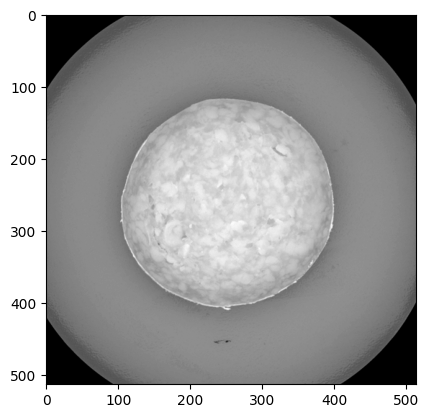

In [38]:
import matplotlib.pyplot as plt

plt.imshow(multiIm[:, :, 13], cmap="gray")

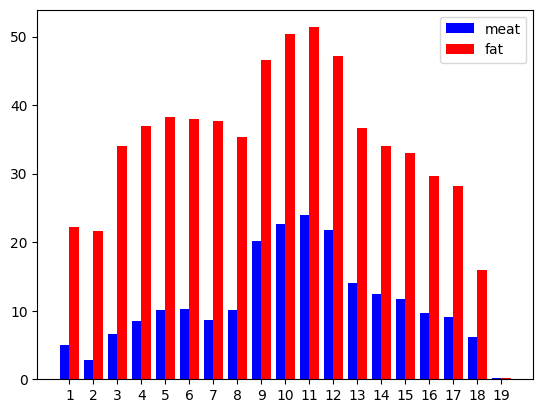

In [39]:
import numpy as np

fatPix, fatR, fatC = hf.getPix(multiIm, annotationIm[:, :, 1])
meatPix, meatR, meatC = hf.getPix(multiIm, annotationIm[:, :, 2])

x = np.arange(1, 20)
width = 0.4
plt.figure()
plt.bar(x, np.var(meatPix, 0), width, color="b", label="meat")
offset = width
plt.bar(x + offset, np.var(fatPix, 0), width, color="r", label="fat")
plt.xticks(x + width / 2, x)
plt.legend()
plt.show()

So, that's after reading the section
### Formulation of the mathematical model:
#### Describe the mathematical model
The goal of the model is to classificy the pixel and meat and fat.

The model simply assumes that the samples are normally distributed with different means and standard deviations.
#### Why do we expect it to work?
* Assuming normal distrbituion: usually biological data is normally distributed.
* We assume the means should be different - from looking at the data
#### What are the limitations of the model?
* The assumption of the same standard deviation is simply wrong, given the plot.
* The assumption of the independence - It is false, because of the location dependence. This is not a noise, if a pixel is white, then likely its surrounding is white as well. I do not think it breaks down the model, but is a missed opportunity. However, it should hold across the bigger window.

### Analysis of the data



#### Investigate the data
* The histgram function is not normalized, so simply more pixels = higher; when comparing both of them.

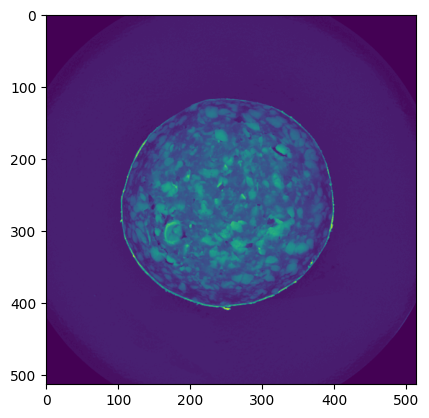

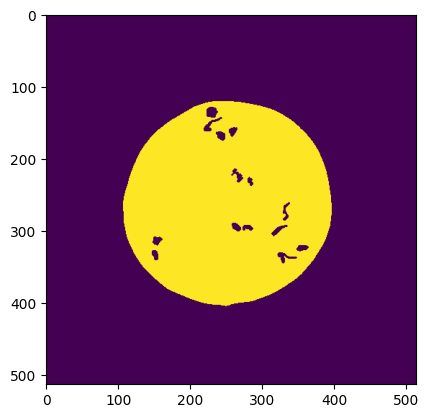

[[17 12 16 ... 48 44  2]
 [17 11 16 ... 47 43  2]
 [17 11 15 ... 47 44  2]
 ...
 [23 18 24 ... 53 48  1]
 [26 21 27 ... 53 49  1]
 [25 21 26 ... 54 48  1]]


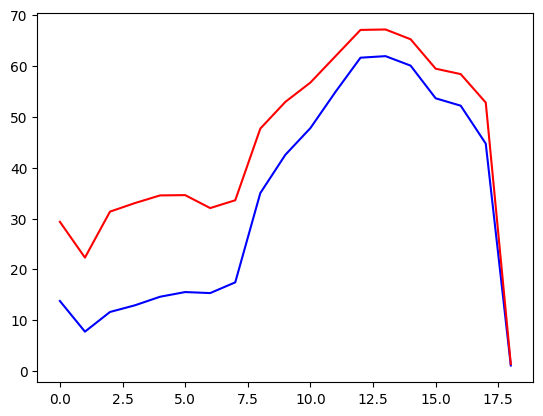

In [40]:
multiIm, annotationIm = hf.loadMulti(
    "multispectral_day20.mat", "annotation_day20.png", dirIn
)
# %%
# Show image of spectral band 7
plt.imshow(multiIm[:, :, 6])
plt.show()

# %%
# annotationIm is a binary image with 3 layers
annotationIm.shape

# %%
# In each layer we have a binary image:
# 0 - background with salami
# 1 fat annotation
# 2 meat annotation

# Here we show the meat annotation
plt.imshow(annotationIm[:, :, 0])
plt.show()

# %%
# The function getPix extracts the multi spectral pixels from the annotation
# Here is an example with meat- and fat annotation
fatPix, fatR, fatC = hf.getPix(multiIm, annotationIm[:, :, 1])
meatPix, meatR, meatC = hf.getPix(multiIm, annotationIm[:, :, 2])

# %%
print(fatPix)
# %%
# Here we plot the mean values for pixels with meat and fat respectively
plt.plot(np.mean(meatPix, 0), "b")
plt.plot(np.mean(fatPix, 0), "r")
plt.show()


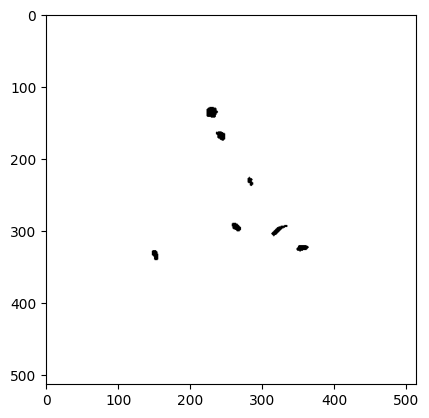

array([[[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       ...,

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]]

In [41]:
# %%
# The function setImagePix produces a colour image
# where the pixel coordinates are given as input
# Load RGB image
imRGB = plt.imread(dirIn + "color_day20.png")

# Pixel coordinates for the fat annotation
fatPix, fatR, fatC = hf.getPix(multiIm, annotationIm[:, :, 1])

# Concatenate the pixel coordinates to a matrix
pixId = np.stack((fatR, fatC), axis=1)

# Make the new images
rgbOut = hf.setImagePix(imRGB, pixId)
plt.imshow(rgbOut, cmap="gray")
plt.show()


# %%
rgbOut


#### Spectral distribution

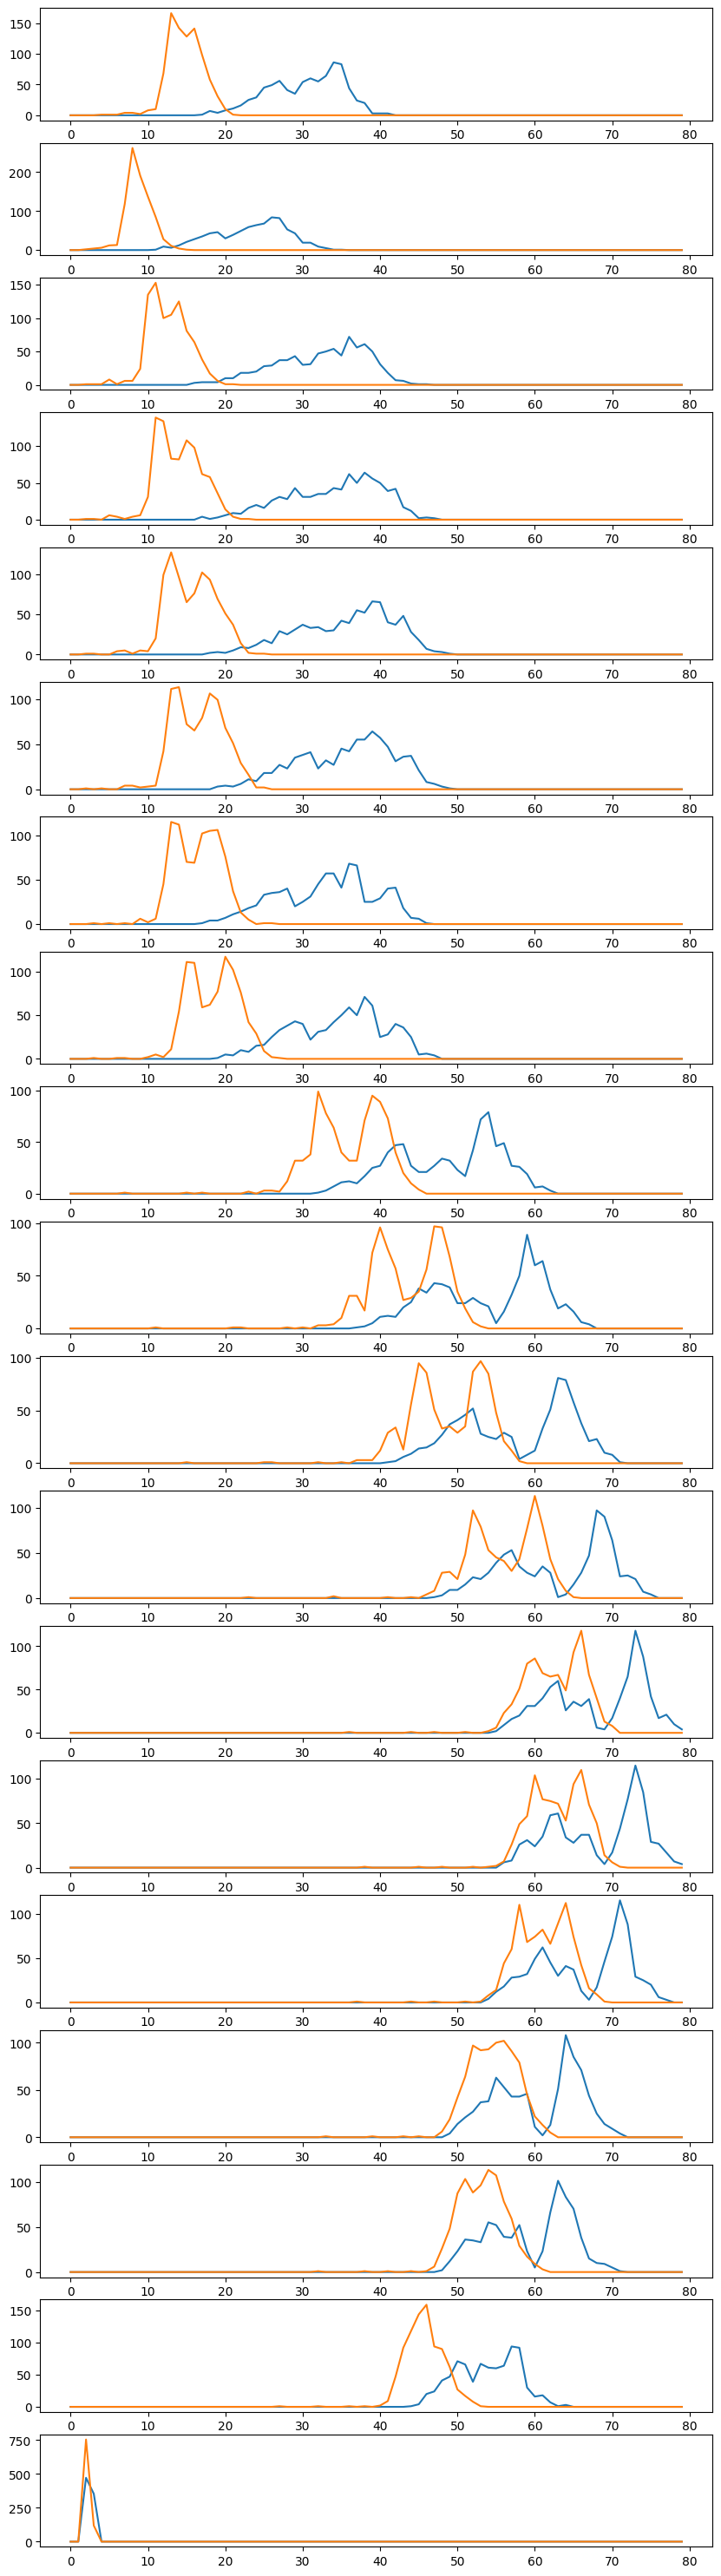

In [42]:
n_layers = 19
fig, ax = plt.subplots(n_layers, 1, figsize=(10, 2 * n_layers))
hist_pairs = []
for layer_id in range(0, n_layers):
    h = hf.showHistograms(
        multiIm, annotationIm[:, :, 1:3], layer_id, False, ["fat", "meat"]
    )
    hist_pairs.append(h)
    ax[layer_id].plot(h[0:80, :])
plt.show()


In [43]:
hist_pairs

[array([[  0.,   0.],
        [  0.,   0.],
        [  0.,   0.],
        [  0.,   0.],
        [  0.,   1.],
        [  0.,   1.],
        [  0.,   1.],
        [  0.,   4.],
        [  0.,   4.],
        [  0.,   2.],
        [  0.,   8.],
        [  0.,  10.],
        [  0.,  68.],
        [  0., 166.],
        [  0., 142.],
        [  0., 128.],
        [  0., 141.],
        [  1.,  98.],
        [  7.,  58.],
        [  4.,  31.],
        [  8.,  10.],
        [ 11.,   1.],
        [ 16.,   0.],
        [ 25.,   0.],
        [ 29.,   0.],
        [ 45.,   0.],
        [ 49.,   0.],
        [ 56.,   0.],
        [ 41.,   0.],
        [ 35.,   0.],
        [ 54.,   0.],
        [ 60.,   0.],
        [ 55.,   0.],
        [ 64.,   0.],
        [ 86.,   0.],
        [ 83.,   0.],
        [ 44.,   0.],
        [ 24.,   0.],
        [ 20.,   0.],
        [  3.,   0.],
        [  3.,   0.],
        [  3.,   0.],
        [  0.,   0.],
        [  0.,   0.],
        [  0.,   0.],
        [ 

#### Is it a reasonable assumption that each pixel is either meat or fat?
I think mostly it is a reasonable assumption, though I am indeed seeing that sometimes, fat is 'seen' through a thin layer of meat atop.#


### Threshold value for a single spectral band

1. Calculate the threshold value t for all spectral bands for day 1.
2. Calculate the error rate for each spectral band.
3. Identify the spectral band, which has the best discriminative properties for meat and fat.
4. Classify the entire image of the salami for day 1, and visualise it.

#### Helper functions

In [44]:
rgbOut.shape

(514, 514, 3)

In [45]:
def LSD_discriminant(mu, var, prior):
    return lambda x: x * mu / var - mu**2 / (var * 2) + np.log(prior)


def LSD_classifier(mu1, var1, prior1, mu2, var2, prior2):
    disc1 = LSD_discriminant(mu1, var1, prior1)
    disc2 = LSD_discriminant(mu2, var2, prior2)
    return lambda x: 1 if disc1(x) > disc2(x) else 0


def class_hat_mean(x):
    return np.mean(x)


def pooled_hat_var(x, y):
    x_hat_var = np.var(x, axis=0)
    y_hat_var = np.var(y, axis=0)
    n_x = len(x)
    n_y = len(y)
    return ((n_x - 1) * x_hat_var + (n_y - 1) * y_hat_var) / (n_x + n_y - 2)


def prior(x):
    total = 514 * 514
    return x.shape[0] / total


### test for day one

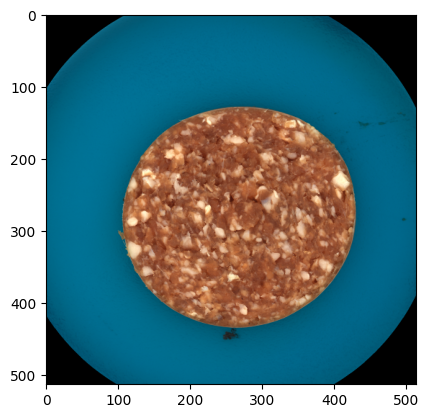

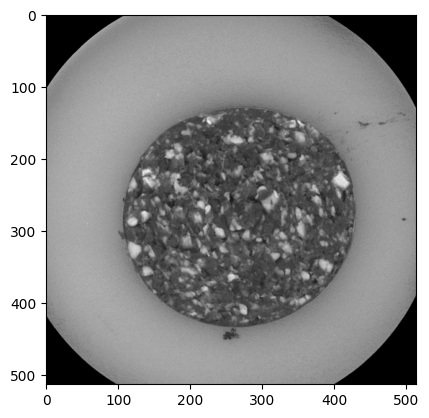

In [ ]:
multiIm1, annotationIm1 = hf.loadMulti(
    "multispectral_day01.mat", "annotation_day01.png", dirIn
)
fatPix1, fatR1, fatC1 = hf.getPix(multiIm1, annotationIm1[:, :, 1])
meatPix1, meatR1, meatC1 = hf.getPix(multiIm1, annotationIm1[:, :, 2])

plt.imshow(plt.imread("./data/color_day01.png"))
### for day one
fatPix1l1 = fatPix1[:, 0]
meatPix1l1 = meatPix1[:, 0]
layer_1 = multiIm1[:, :, 0]

fat_mean_1l1 = class_hat_mean(fatPix1l1)
meat_mean_1l1 = class_hat_mean(meatPix1l1)

fat_meat_pooled_var_1l1 = pooled_hat_var(meatPix1l1, fatPix1l1)

prior_fat_1l1 = prior(fatPix1l1)
prior_meat_1l1 = prior(meatPix1l1)

LSD_1l1 = LSD_classifier(
    fat_mean_1l1,
    fat_meat_pooled_var_1l1,
    prior_fat_1l1,
    meat_mean_1l1,
    fat_meat_pooled_var_1l1,
    prior_meat_1l1,
)

plt.figure()
plt.imshow(layer_1, cmap="gray")
plt.show()


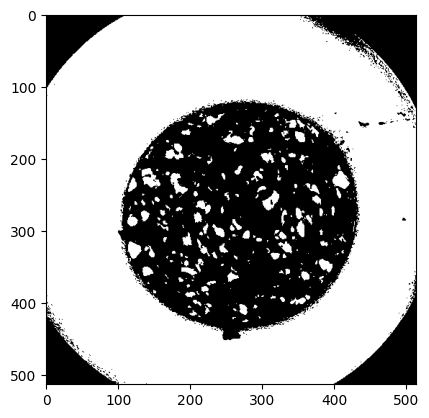

In [47]:
labeled_layer_1 = np.zeros((multiIm1.shape[0], multiIm1.shape[1]))

for i in range(layer_1.shape[0]):
    for j in range(layer_1.shape[1]):
        labeled_layer_1[i, j] = LSD_1l1(layer_1[i, j])
plt.figure()
plt.imshow(labeled_layer_1, cmap="gray")
plt.show()

In [48]:
labeled_layer_1[*[2, 3]]

np.float64(0.0)

In [49]:
### Calculate the accuracy of the classifier for layer 1 on the known pixels
fatPixId1 = np.stack((fatR1, fatC1), axis=1)
meatPixId1 = np.stack((meatR1, meatC1), axis=1)

correct = 0
total = fatPixId1.shape[0] + meatPixId1.shape[0]
for pix in fatPixId1:
    pred_val = labeled_layer_1[*pix]
    correct += pred_val == 1
for pix in meatPixId1:
    pred_val = labeled_layer_1[*pix]
    correct += pred_val == 0
print(correct / total)

0.9895652173913043


#### All steps in one go

In [50]:
error_rates = []
for layer_id in range(n_layers):
    ### for day one
    fatPix1l = fatPix1[:, layer_id]
    meatPix1l = meatPix1[:, layer_id]
    layer = multiIm1[:, :, layer_id]

    fat_mean_1l = class_hat_mean(fatPix1l)
    meat_mean_1l = class_hat_mean(meatPix1l)

    fat_var_1l = pooled_hat_var(fatPix1l, meatPix1l)
    meat_var_1l = pooled_hat_var(meatPix1l, fatPix1l)

    prior_fat_1l = prior(fatPix1l)
    prior_meat_1l = prior(meatPix1l)

    LSD_1l = LSD_classifier(
        fat_mean_1l,
        fat_var_1l,
        prior_fat_1l,
        meat_mean_1l,
        meat_var_1l,
        prior_meat_1l,
    )
    labeled_layer = np.zeros((multiIm1.shape[0], multiIm1.shape[1]))

    for i in range(layer.shape[0]):
        for j in range(layer.shape[1]):
            labeled_layer[i, j] = LSD_1l1(layer[i, j])
    # plt.figure()
    # plt.imshow(labeled_layer, cmap="gray")
    # plt.show()

    correct = 0
    total = fatPixId1.shape[0] + meatPixId1.shape[0]
    for pix in fatPixId1:
        pred_val = labeled_layer[*pix]
        correct += pred_val == 1
    for pix in meatPixId1:
        pred_val = labeled_layer[*pix]
        correct += pred_val == 0
    error_rate = 1 - correct / total
    error_rates.append(error_rate)

#### Identify the spectral band, which has the best discriminative properties for meat and fat.

In [51]:
print(np.min(error_rates))
print(np.argmin(error_rates))
best_layer_id = np.argmin(error_rates)

0.0005797101449275255
4


#### Classify the entire image of the salami for day 1, and visualise it.

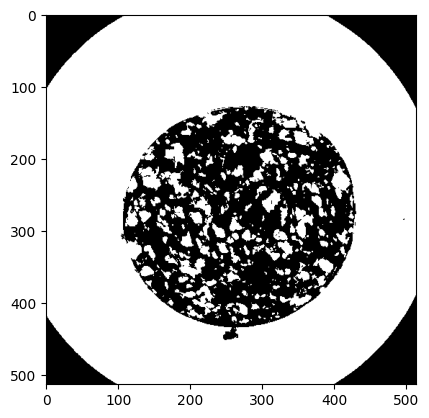

In [52]:
### for day one
fatPix1l = fatPix1[:, best_layer_id]
meatPix1l = meatPix1[:, best_layer_id]
layer = multiIm1[:, :, best_layer_id]

fat_mean_1l = class_hat_mean(fatPix1l)
meat_mean_1l = class_hat_mean(meatPix1l)

fat_meat_pooled_var_1l = pooled_hat_var(fatPix1l, meatPix1l)

prior_fat_1l = prior(fatPix1l)
prior_meat_1l = prior(meatPix1l)

LSD_1l = LSD_classifier(
    fat_mean_1l,
    fat_meat_pooled_var_1l,
    prior_fat_1l,
    meat_mean_1l,
    fat_meat_pooled_var_1l,
    prior_meat_1l,
)
labeled_layer = np.zeros((multiIm1.shape[0], multiIm1.shape[1]))

for i in range(layer.shape[0]):
    for j in range(layer.shape[1]):
        labeled_layer[i, j] = LSD_1l1(layer[i, j])
plt.figure()
plt.imshow(labeled_layer, cmap="gray")
plt.show()


### Threshold value for a single spectral band
1. Calculate the threshold value t for all spectral bands for day 1.
2. Calculate the error rate for each spectral band.
3. Identify the spectral band, which has the best discriminative properties for meat and fat.
4. Classify the entire image of the salami for day 1, and visualise it.

In [33]:
def class_md_hat_mean(X):
    """Assumes observations in X are in rows, and dimensions in columns"""
    return np.mean(X, axis=0)


def class_hat_covar(X, X_hat_mean=None):
    """Observations are in row. Computes covariance matrix"""
    if X_hat_mean is None:
        X_hat_mean = class_md_hat_mean(X)
    X_c = X - X_hat_mean
    n = X.shape[0]
    return 1 / (n - 1) * X_c.T @ X_c


def pool_hat_covar(X, Y):
    """Observations are in row. Computes pooled covariance matrix"""
    X_hat_covar = class_hat_covar(X)
    Y_hat_covar = class_hat_covar(Y)
    n_X = X.shape[0]
    n_Y = Y.shape[0]
    return ((n_X - 1) * X_hat_covar + (n_Y - 1) * Y_hat_covar) / (n_X + n_Y - 2)


def prior(x):
    total = 514 * 514
    return x.shape[0] / total


### test for day one


def md_LSD_discriminant(X_hat_mean, X_pool_covar, prior):
    """Multi dimensional, observation provided as a row"""
    inv_covar = np.linalg.inv(X_pool_covar)
    return lambda x: (
        x @ inv_covar @ X_hat_mean.T
        - 1 / 2 * X_hat_mean @ inv_covar @ X_hat_mean.T
        + np.log(prior)
    )


def md_LSD_classifier(X_hat_mean_1, X_hat_mean_2, prior_1, prior_2, X_pool_hat_covar):
    disc1 = md_LSD_discriminant(X_hat_mean_1, X_pool_hat_covar, prior_1)
    disc2 = md_LSD_discriminant(X_hat_mean_2, X_pool_hat_covar, prior_2)
    # print(disc1(x), disc2(x))
    return lambda x: 1 if disc1(x) > disc2(x) else 0


In [10]:
import helper_functions.helpFunctions as hf
import matplotlib.pyplot as plt
import numpy as np

dirIn = "./data/"


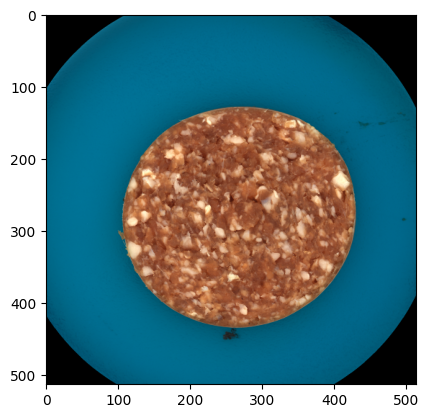

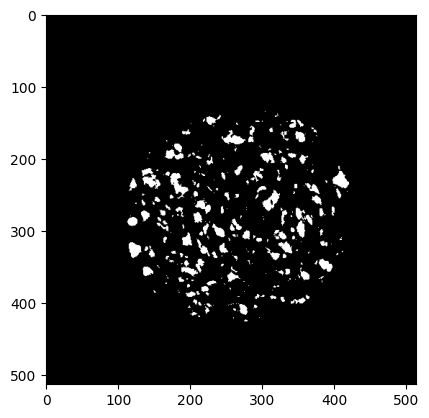

In [34]:
# multivariate case


multiIm1, annotationIm1 = hf.loadMulti(
    "multispectral_day01.mat", "annotation_day01.png", dirIn
)
fatPix1, fatR1, fatC1 = hf.getPix(multiIm1, annotationIm1[:, :, 1])
meatPix1, meatR1, meatC1 = hf.getPix(multiIm1, annotationIm1[:, :, 2])

plt.imshow(plt.imread("./data/color_day01.png"))
### for day one

fat_mean_1 = class_md_hat_mean(fatPix1)
meat_mean_1 = class_md_hat_mean(meatPix1)

fat_mean_pooled_covar = pool_hat_covar(fatPix1, meatPix1)


prior_fat_1 = prior(fatPix1)
prior_meat_1 = prior(meatPix1)

LSD_1 = md_LSD_classifier(
    fat_mean_1,
    meat_mean_1,
    prior_fat_1,
    prior_meat_1,
    fat_mean_pooled_covar,
)

labeled_multiIm1 = np.zeros((multiIm1.shape[0], multiIm1.shape[1]))

for i in range(multiIm1.shape[0]):
    for j in range(multiIm1.shape[1]):
        labeled_multiIm1[i, j] = LSD_1(multiIm1[i, j])
plt.figure()
plt.imshow(labeled_multiIm1, cmap="gray")
plt.show()

In [35]:
### Calculate the accuracy of the classifier for layer 1 on the known pixels
fatPixId1 = np.stack((fatR1, fatC1), axis=1)
meatPixId1 = np.stack((meatR1, meatC1), axis=1)

correct = 0
total = fatPixId1.shape[0] + meatPixId1.shape[0]
for pix in fatPixId1:
    pred_val = labeled_multiIm1[*pix]
    correct += pred_val == 1
for pix in meatPixId1:
    pred_val = labeled_multiIm1[*pix]
    correct += pred_val == 0
print(correct / total)

0.9942028985507246
